# code_041 · Representations and storage contracts

**Book:** section 8.5. A dataset-construction laboratory using invented structural-monitoring records. Prerequisites: Python arrays, tables and Chapter 7's information boundaries. Restart and run all cells. Every import, helper and input is here; no ordinary-run files, network, credentials, GPU or private helper are required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_08_GUIDE.md), [run evidence](../CHAPTER_08_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_041).

Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0, CPU. Allow one minute to execute and 30–60 minutes to interpret. These are scoped data-contract experiments rather than exhaustive estimator API studies. Construction identities have no training/test interpretation. The sampling laboratory alone fits two fixed constant predictors and protects an independent final population. No engineering reliability or causal maintenance conclusion follows.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=841;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 841


<a id="views"></a>
## Several views, one source contract

Six members have stable IDs, lengths in metres and four daily readings in mm. Member 2/day 2 has no record; member 0/day 0 is a genuine zero. Edges connect physical neighbors within two buildings. Node row positions are not IDs. A wide pivot needs a fixed time/member order and an explicit missingness mask. Zero filling is only a storage placeholder interpreted together with that mask; it is not a trained imputation model. No pretraining, fitted scaling or outcome fitting occurs.


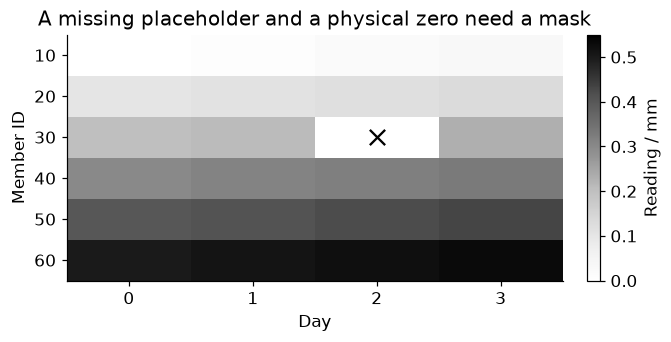

In [2]:
import io,hashlib
ids=np.array([10,20,30,40,50,60],dtype=np.int64);length=np.array([2.,3.,4.,2.5,3.5,4.5]);edges=np.array([[10,20],[20,30],[40,50],[50,60]],dtype=np.int64)
records=pd.DataFrame([(int(mid),t,.1*j+.01*t) for j,mid in enumerate(ids) for t in range(4) if not (j==2 and t==2)],columns=['member_id','day','reading_mm'])
wide=records.pivot(index='member_id',columns='day',values='reading_mm').reindex(index=ids,columns=range(4));mask=wide.notna().to_numpy();values=wide.fillna(0).to_numpy(dtype=np.float64)
assert values.shape==mask.shape==(6,4) and values[0,0]==0 and mask[0,0]
assert values[2,2]==0 and not mask[2,2] and mask.sum()==len(records)
restored=pd.DataFrame(np.where(mask,values,np.nan),index=ids,columns=range(4))
assert np.allclose(restored.to_numpy(),wide.to_numpy(),equal_nan=True)
fig,ax=plt.subplots(figsize=(6,3));im=ax.imshow(values,cmap='Greys',vmin=0,vmax=.55,aspect='auto');ax.scatter([2],[2],marker='x',s=100,color='black');ax.set(xticks=range(4),yticks=range(6),yticklabels=ids,xlabel='Day',ylabel='Member ID',title='A missing placeholder and a physical zero need a mask');fig.colorbar(im,ax=ax,label='Reading / mm');plt.show()
RESULTS['observation_count']=len(records);RESULTS['sequence_shape']=list(values.shape);RESULTS['missing_values']=int((~mask).sum())


<a id="graph"></a>
## Relabel positions without changing relationships

Map stable IDs into array positions and symmetrize each undirected edge exactly once. A neighbor-mean operation should change only its output order when input rows and adjacency are consistently permuted. Leaving adjacency fixed while shuffling features produces another problem. Isolated nodes require a separate explicit convention; this fixture has none. The graph is a data view and a single algebraic operation, not a trained GNN.


In [3]:
def adjacency(order):
 pos={int(mid):j for j,mid in enumerate(order)};A=np.zeros((len(order),len(order)))
 for u,v in edges:
  assert int(u) in pos and int(v) in pos
  i,j=pos[int(u)],pos[int(v)];A[i,j]=A[j,i]=1
 return A
A=adjacency(ids);assert np.array_equal(A,A.T) and np.all(A.sum(1)>0)
neighbor=A@length/A.sum(1)
perm=np.array([3,0,5,1,4,2]);other_ids=ids[perm];B=adjacency(other_ids);other=length[perm]
assert np.allclose(B@other/B.sum(1),neighbor[perm])
assert not np.allclose(A@other/A.sum(1),neighbor[perm])
RESULTS['graph_permutation_preserves_values']=True;RESULTS['neighbor_mean_length_m']=neighbor.tolist();RESULTS['undirected_edges']=len(edges)


<a id="storage"></a>
## Persist arrays together with their meanings

Use an in-memory NumPy archive so ordinary execution reads no files. Preserve IDs, edge IDs, sequence values and boolean mask; load with allow_pickle=False. Serialize a separate sorted JSON schema naming axes, units, edge semantics and version. The archive is a demonstration, not a recommendation for every workload. Linked columnar tables suit scans; event logs retain history; graph arrays need order mappings; large chunks and meshes need topology and boundary metadata. A file extension cannot supply missing semantics.


In [4]:
schema={'version':'1.0','node_key':'stable member_id','node_order':ids.tolist(),'sequence_axes':['member','day'],'days':list(range(4)),'units':{'length':'m','reading':'mm'},'edges':'undirected physical neighbors; each stored once','missing':'boolean mask; zero is placeholder only where false','dtypes':{'ids':'int64','values':'float64','mask':'bool'}}
encoded=json.dumps(schema,sort_keys=True,separators=(',',':')).encode();assert json.loads(encoded)['units']['reading']=='mm'
buffer=io.BytesIO();np.savez(buffer,ids=ids,length_m=length,edges=edges,values_mm=values,observed=mask);buffer.seek(0)
with np.load(buffer,allow_pickle=False) as data:
 assert np.array_equal(data['ids'],ids) and np.array_equal(data['edges'],edges)
 assert np.array_equal(data['observed'],mask) and np.array_equal(data['values_mm'],values)
 assert data['values_mm'].dtype==np.dtype('float64') and data['observed'].dtype==np.dtype('bool')
wrong_units={**schema,'units':{'length':'cm','reading':'mm'}};assert wrong_units['units']!=schema['units']
length_cm=length*100;assert np.allclose(length_cm/100,length)
RESULTS['schema_sha256']=hashlib.sha256(encoded).hexdigest();RESULTS['safe_numeric_roundtrip']=True


<a id="mesh"></a>
## A point cloud does not retain a mesh's interpolation rule

A separate square fixture uses coordinates in metres and nodal temperatures [290,300,310,295] K. Two valid triangulations use different diagonals. Their piecewise-linear interpolations at the center are 300 K and 297.5 K. The nodal values and coordinates alone therefore do not define the interpolated field. This is geometry/algebra, not a PDE solve or physical temperature validation. Connectivity, coordinate frame, field location and boundary tags belong in a mesh contract. The left boundary is tagged for specified nodal temperatures; no governing equation or other boundary condition is solved here.


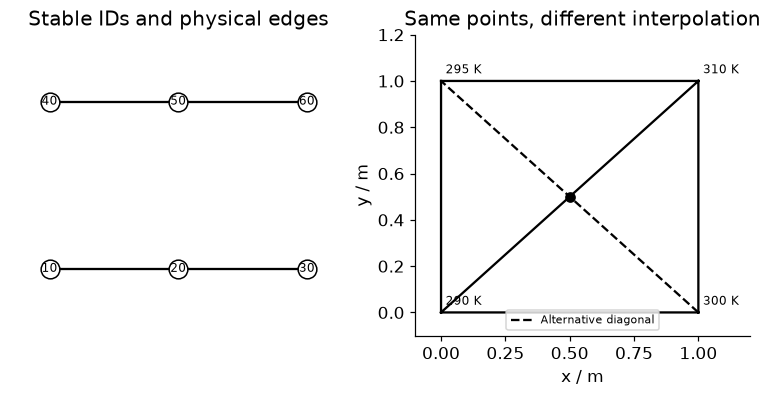

In [5]:
xy=np.array([[0.,0.],[1.,0.],[1.,1.],[0.,1.]]);temperature=np.array([290.,300.,310.,295.]);tri_a=np.array([[0,1,2],[0,2,3]]);tri_b=np.array([[0,1,3],[1,2,3]])
left_boundary=np.array([0,3]);assert np.all(xy[left_boundary,0]==0)
center_a=float(temperature[[0,2]].mean());center_b=float(temperature[[1,3]].mean());assert center_a==300 and center_b==297.5
assert tri_a.min()==0 and tri_a.max()<len(xy) and len(temperature)==len(xy)
fig,axes=plt.subplots(1,2,figsize=(6.8,3.5))
positions=np.array([[0,0],[1,0],[2,0],[0,1],[1,1],[2,1]])
for u,v in edges:
 i=np.flatnonzero(ids==u)[0];j=np.flatnonzero(ids==v)[0];axes[0].plot(positions[[i,j],0],positions[[i,j],1],'k-')
axes[0].scatter(positions[:,0],positions[:,1],s=150,facecolors='white',edgecolors='black',zorder=3)
for j,mid in enumerate(ids):axes[0].text(*positions[j],str(mid),ha='center',va='center',fontsize=8)
axes[0].set(xlim=(-.3,2.3),ylim=(-.4,1.4),title='Stable IDs and physical edges');axes[0].axis('off')
axes[1].triplot(xy[:,0],xy[:,1],tri_a,color='black');axes[1].plot([1,0],[0,1],'k--',label='Alternative diagonal')
for j,t in enumerate(temperature):axes[1].annotate(f'{int(t)} K',xy[j],xytext=(3,5),textcoords='offset points',fontsize=8)
axes[1].plot(.5,.5,'ko');axes[1].set(xlim=(-.1,1.2),ylim=(-.1,1.2),xlabel='x / m',ylabel='y / m',title='Same points, different interpolation');axes[1].legend(fontsize=7,loc='lower center');plt.show()
RESULTS['mesh_center_temperature_K']={'diagonal_0_2':center_a,'diagonal_1_3':center_b};RESULTS['schema']=schema


<a id="exercises"></a>
## Exercises and hints

1. Shuffle node rows without remapping edge positions; predict which invariant fails.
2. Convert a length source from cm to m and record the conversion/version instead of relabelling values.
3. Add a mesh with a missing boundary tag. Specify which scientific task would require that tag.
4. Choose an event log or columnar table for a larger workload, preserving primary keys, availability versions, units and schema migration history.

**Hints:** the wide view deliberately loses per-event revision history; the source log must remain available. The archive round trip proves value preservation only under its explicit schema, not dataset validity. A JSON digest alone does not retain array payloads. In production store both payload and contract. See official [NumPy save/load formats](https://numpy.org/doc/stable/reference/generated/numpy.savez.html). No additional dependency is required for this in-memory example.


In [6]:
summary={'example_id':'code_041','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['linked tables wide views sequences and graph edge lists', 'node ID order and permutation consistency', 'missingness masks versus physical zero', 'mesh connectivity changes interpolation', 'versioned schema units and safe numeric round trips'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["linked tables wide views sequences and graph edge lists", "node ID order and permutation consistency", "missingness masks versus physical zero", "mesh connectivity changes interpolation", "versioned schema units and safe numeric round trips"], "elapsed_seconds": 1.309, "example_id": "code_041", "hardware": "Darwin arm64 CPU", "results": {"graph_permutation_preserves_values": true, "mesh_center_temperature_K": {"diagonal_0_2": 300.0, "diagonal_1_3": 297.5}, "missing_values": 1, "neighbor_mean_length_m": [3.0, 3.0, 3.0, 3.5, 3.5, 3.5], "observation_count": 23, "safe_numeric_roundtrip": true, "schema": {"days": [0, 1, 2, 3], "dtypes": {"ids": "int64", "mask": "bool", "values": "float64"}, "edges": "undirected physical neighbors; each stored once", "missing": "boolean mask; zero is placeholder only where false", "node_key": "stable member_id", "node_order": [10, 20, 30, 40, 50, 60], "sequence_axes": ["member", "day"], "units": {"length": "